# Re-incorporating cut-off Pauli strings (LiH prototype)

Strings with $|c| \geq$ cutoff are grouped with $k$-commuting sorted insertion. The cut-off strings are not discarded but measured in extra groups:

* all cut-off **Z-only** strings in a single group (they all commute),
* every other cut-off string **individually**.

Shots for precision $\epsilon$ with optimal allocation: $N = \left(\sum_g \sqrt{\mathrm{Var}_\psi(H_g)}\right)^2/\epsilon^2$, summed over all groups (kept + Z group + singletons), using the exact ground state. The reference is cutoff = 0 (all strings grouped). "Computation time" is the wall time of the $k$-commuting grouping (`kcommute.get_si_sets`), which is the step the cutoff is meant to speed up.

In [1]:
import os
import pickle
import sys
import time

sys.path.append("..")

import cirq
import matplotlib.pyplot as plt
import numpy as np
import openfermion as of
import scipy.sparse.linalg

import kcommute

In [2]:
# Parameters.
cutoffs = [0.0, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]  # 0 = no cutoff (reference).
k_values = [1, 2, 3, 4, 6, 12]
epsilon = 1.6e-3  # Ha (chemical accuracy).
results_file = "lih_cutoff_results.pkl"

## Hamiltonian and ground state

In [3]:
# LiH, STO-3G, 1.45 Angstrom (bundled with OpenFermion).
data_dir = os.path.join(os.path.dirname(of.__file__), "testing", "data")
molecule = of.MolecularData(filename=os.path.join(data_dir, "H1-Li1_sto-3g_singlet_1.45.hdf5"))
qubit_hamiltonian = of.jordan_wigner(of.get_fermion_operator(molecule.get_molecular_hamiltonian()))
nqubits = of.count_qubits(qubit_hamiltonian)
qubits = cirq.LineQubit.range(nqubits)

# Non-identity terms, as {term: real coefficient}.
terms = {t: c.real for t, c in qubit_hamiltonian.terms.items() if t != ()}
print(f"{nqubits} qubits, {len(terms)} non-identity Pauli strings")

# Exact ground state.
energies, vecs = scipy.sparse.linalg.eigsh(of.get_sparse_operator(qubit_hamiltonian), k=1, which="SA")
psi = vecs[:, 0]
print(f"Ground-state energy: {energies[0]:.8f} Ha (FCI: {molecule.fci_energy:.8f} Ha)")

12 qubits, 630 non-identity Pauli strings
Ground-state energy: -7.88098231 Ha (FCI: -7.88098231 Ha)


In [4]:
# P|psi> for every Pauli string, so that the variance of any group O = sum_P c_P P is cheap:
# Var(O) = ||O psi||^2 - <psi|O|psi>^2.
p_psi = {t: of.get_sparse_operator(of.QubitOperator(t), n_qubits=nqubits) @ psi for t in terms}


def group_variance(group_terms):
    o_psi = sum(terms[t] * p_psi[t] for t in group_terms)
    mean = np.vdot(psi, o_psi).real
    return max(np.vdot(o_psi, o_psi).real - mean**2, 0.0)


def pauli_string_to_term(pstring: cirq.PauliString):
    return tuple(sorted((q.x, str(p)) for q, p in pstring.items()))


def is_z_only(term):
    return all(p == "Z" for _, p in term)

## Shot counts for each cutoff and k

In [5]:
results = []  # One record per (cutoff, k).
for cutoff in cutoffs:
    kept = [t for t, c in terms.items() if abs(c) >= cutoff]
    dropped = [t for t, c in terms.items() if abs(c) < cutoff]
    dropped_z = [t for t in dropped if is_z_only(t)]
    dropped_other = [t for t in dropped if not is_z_only(t)]

    # Extra groups for the cut-off strings (independent of k).
    extra_variances = [group_variance([t]) for t in dropped_other]
    if dropped_z:
        extra_variances.append(group_variance(dropped_z))
    n_extra_groups = len(dropped_other) + (1 if dropped_z else 0)

    kept_psum = of.transforms.qubit_operator_to_pauli_sum(
        of.QubitOperator.accumulate(of.QubitOperator(t, terms[t]) for t in kept), qubits
    )
    for k in k_values:
        start = time.perf_counter()
        groups = kcommute.get_si_sets(kept_psum, k=k)
        grouping_time = time.perf_counter() - start

        kept_variances = [group_variance([pauli_string_to_term(p) for p in g]) for g in groups]
        variances = np.array(kept_variances + extra_variances)
        shots = np.sum(np.sqrt(variances)) ** 2 / epsilon**2
        results.append({
            "cutoff": cutoff, "k": k, "n_kept": len(kept), "n_dropped_z": len(dropped_z),
            "n_dropped_other": len(dropped_other), "n_groups_kept": len(groups),
            "n_groups_total": len(groups) + n_extra_groups, "grouping_time": grouping_time, "shots": shots,
        })
    print(f"cutoff {cutoff:g}: kept {len(kept)}, dropped Z-only {len(dropped_z)}, dropped other {len(dropped_other)}")

# Ratio to the no-cutoff shot count at the same k.
reference = {r["k"]: r["shots"] for r in results if r["cutoff"] == 0.0}
for r in results:
    r["shot_ratio"] = r["shots"] / reference[r["k"]]

with open(results_file, "wb") as f:
    pickle.dump({"epsilon": epsilon, "results": results}, f)

cutoff 0: kept 630, dropped Z-only 0, dropped other 0
cutoff 0.001: kept 542, dropped Z-only 0, dropped other 88
cutoff 0.003: kept 322, dropped Z-only 0, dropped other 308
cutoff 0.01: kept 134, dropped Z-only 0, dropped other 496
cutoff 0.03: kept 94, dropped Z-only 0, dropped other 536
cutoff 0.1: kept 17, dropped Z-only 61, dropped other 552


In [6]:
print(f"{'cutoff':>8} {'k':>3} {'groups':>7} {'shots':>10} {'ratio':>6} {'time (s)':>9}")
for r in results:
    print(f"{r['cutoff']:>8g} {r['k']:>3d} {r['n_groups_total']:>7d} {r['shots']:>10.3e} {r['shot_ratio']:>6.2f} {r['grouping_time']:>9.3f}")

  cutoff   k  groups      shots  ratio  time (s)
       0   1     175  2.973e+05   1.00     2.288
       0   2     110  2.516e+05   1.00     1.659
       0   3     111  2.873e+05   1.00     1.295
       0   4      91  2.222e+05   1.00     1.249
       0   6      71  2.472e+05   1.00     1.180
       0  12      41  2.461e+05   1.00     1.503
   0.001   1     231  3.045e+05   1.02     2.510
   0.001   2     172  2.661e+05   1.06     1.191
   0.001   3     188  3.050e+05   1.06     1.822
   0.001   4     166  2.413e+05   1.09     1.065
   0.001   6     149  2.644e+05   1.07     0.912
   0.001  12     126  2.636e+05   1.07     1.495
   0.003   1     389  5.598e+05   1.88     1.770
   0.003   2     357  4.957e+05   1.97     1.081
   0.003   3     364  5.486e+05   1.91     0.916
   0.003   4     356  4.639e+05   2.09     0.794
   0.003   6     346  4.979e+05   2.01     0.495
   0.003  12     331  4.762e+05   1.93     0.342
    0.01   1     513  1.244e+06   4.18     0.356
    0.01   2     509

## Plots

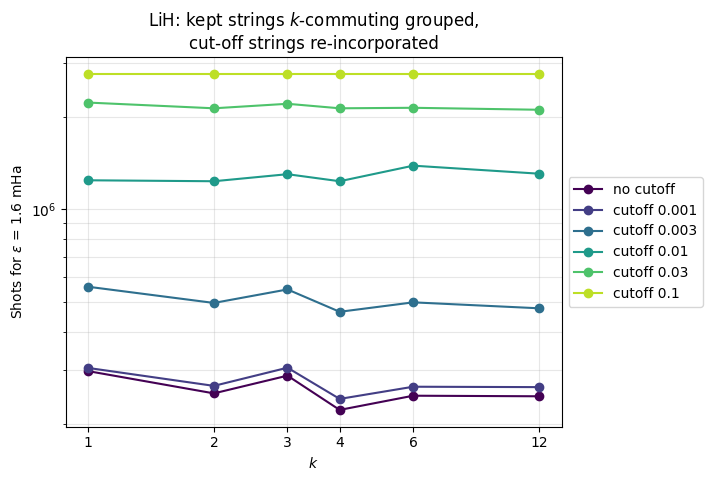

In [7]:
colors = plt.cm.viridis(np.linspace(0, 0.9, len(cutoffs)))

fig, ax = plt.subplots()
for cutoff, color in zip(cutoffs, colors):
    rs = [r for r in results if r["cutoff"] == cutoff]
    label = "no cutoff" if cutoff == 0 else f"cutoff {cutoff:g}"
    ax.plot([r["k"] for r in rs], [r["shots"] for r in rs], "o-", color=color, label=label)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(k_values, [str(k) for k in k_values])
ax.set_xlabel("$k$")
ax.set_ylabel(f"Shots for $\\epsilon$ = {epsilon * 1e3:g} mHa")
ax.set_title("LiH: kept strings $k$-commuting grouped,\ncut-off strings re-incorporated")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid(True, which="both", alpha=0.3)
fig.savefig("lih_shots_vs_k.pdf", bbox_inches="tight")
plt.show()

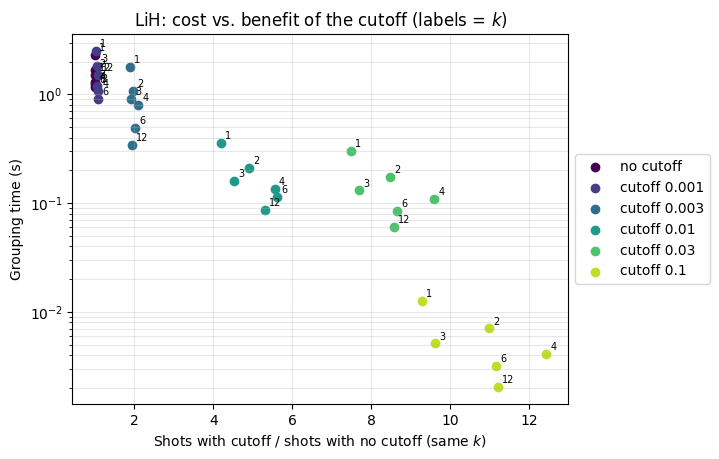

In [8]:
fig, ax = plt.subplots()
for cutoff, color in zip(cutoffs, colors):
    rs = [r for r in results if r["cutoff"] == cutoff]
    label = "no cutoff" if cutoff == 0 else f"cutoff {cutoff:g}"
    ax.scatter([r["shot_ratio"] for r in rs], [r["grouping_time"] for r in rs], color=color, label=label)
    for r in rs:
        ax.annotate(f"{r['k']}", (r["shot_ratio"], r["grouping_time"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.set_yscale("log")
ax.set_xlabel("Shots with cutoff / shots with no cutoff (same $k$)")
ax.set_ylabel("Grouping time (s)")
ax.set_title("LiH: cost vs. benefit of the cutoff (labels = $k$)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid(True, which="both", alpha=0.3)
fig.savefig("lih_time_vs_shot_ratio.pdf", bbox_inches="tight")
plt.show()